In [ ]:
#1 import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#2 load csv file

df = pd.read_csv(r"C:\Users\HPadmin\Downloads\HR-Employee-Attrition.csv")
df.head()

#3 check dataset

#shape
df.shape

#columns
df.columns

#datatypes
df.dtypes

#summary statistics
df.describe()


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [ ]:
#4 handle missing values
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [ ]:
#5 remove duplicate records
df.duplicated().sum()
df = df.drop_duplicates()

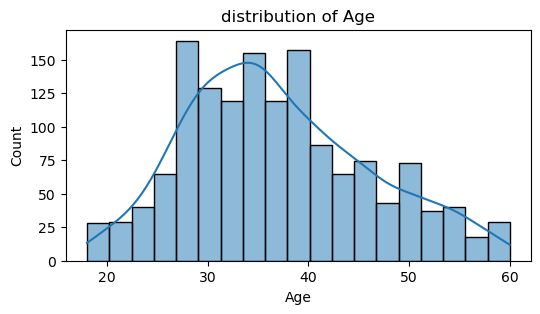

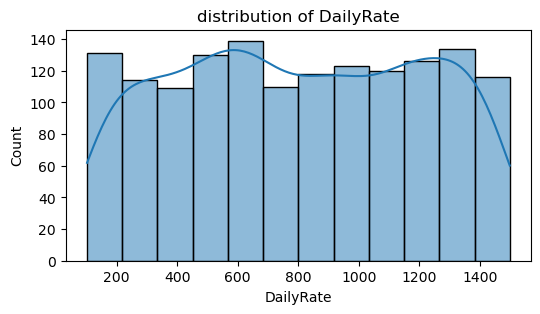

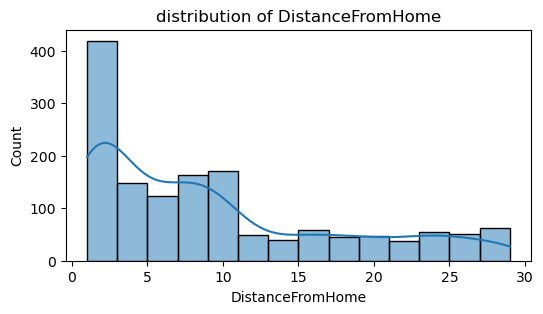

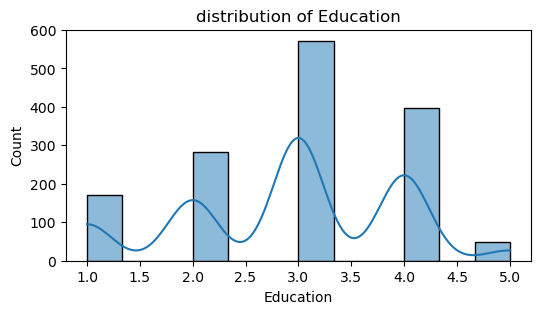

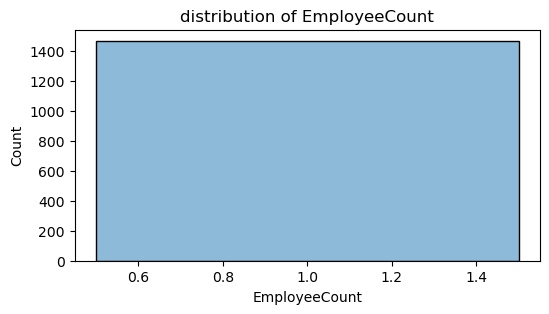

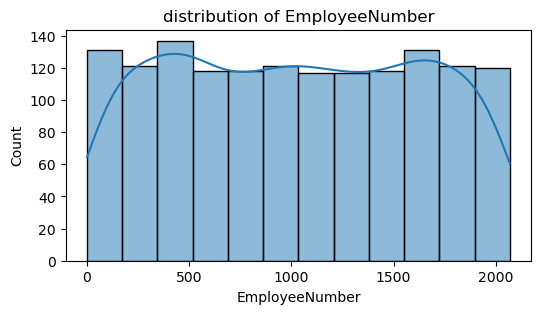

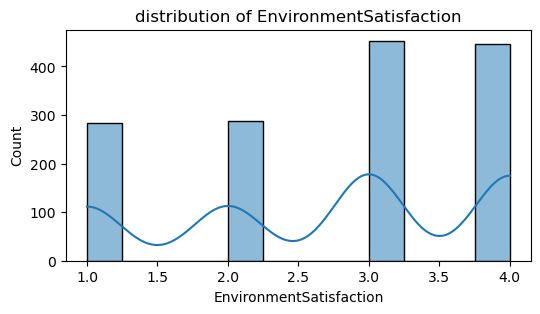

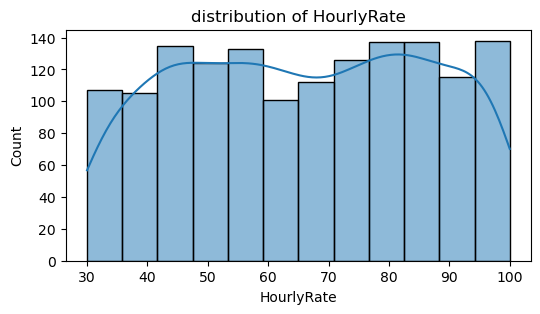

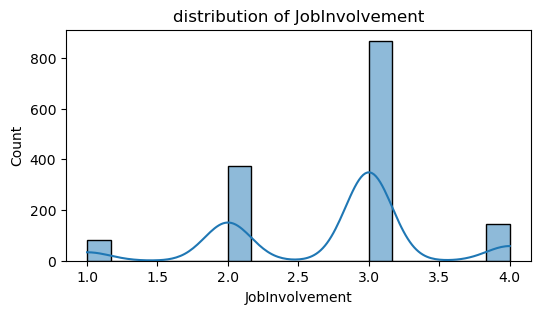

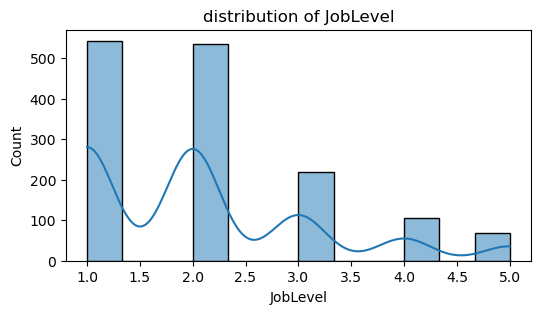

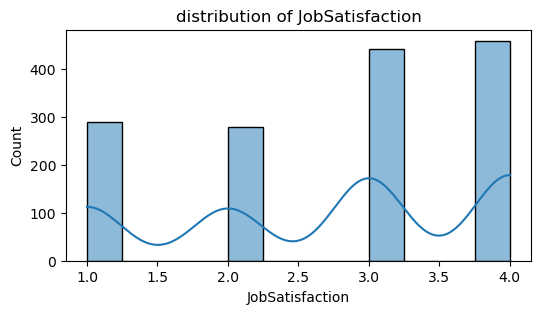

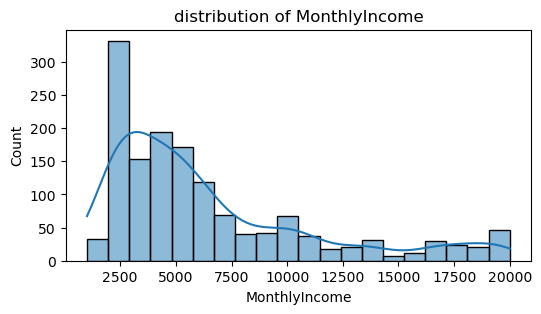

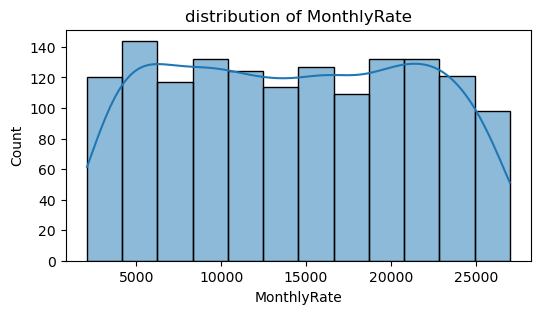

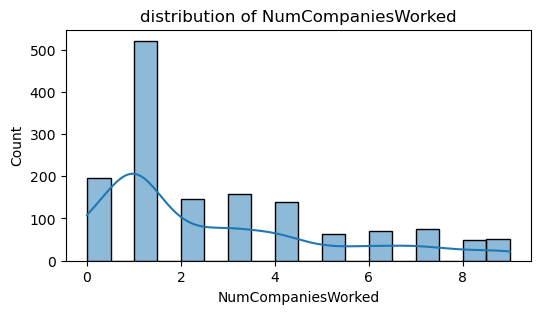

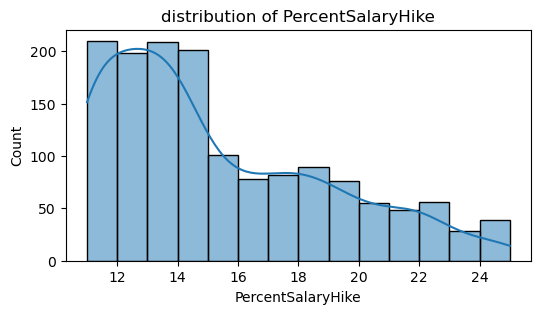

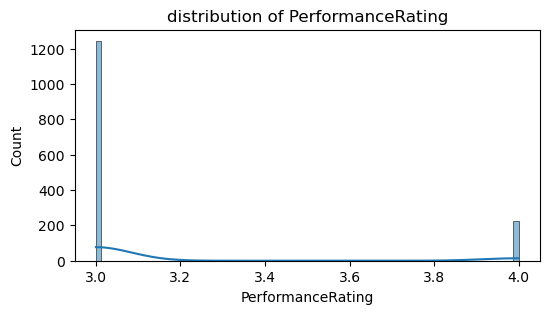

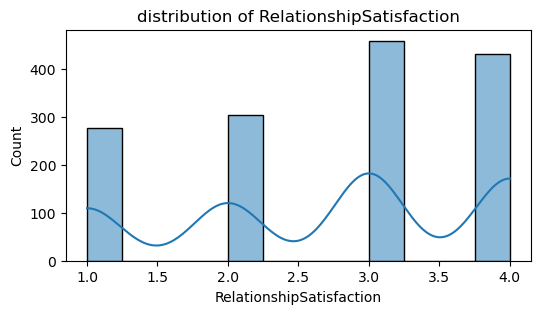

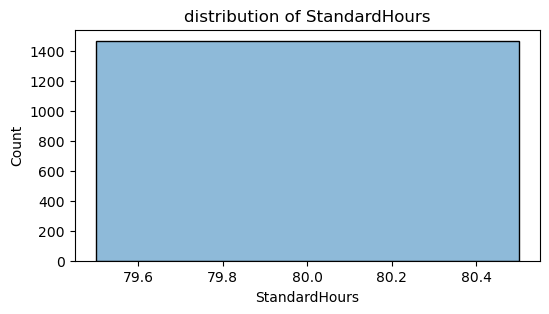

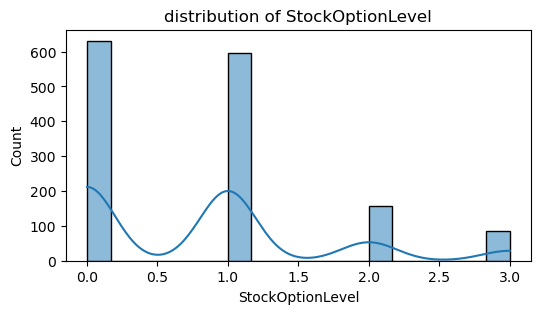

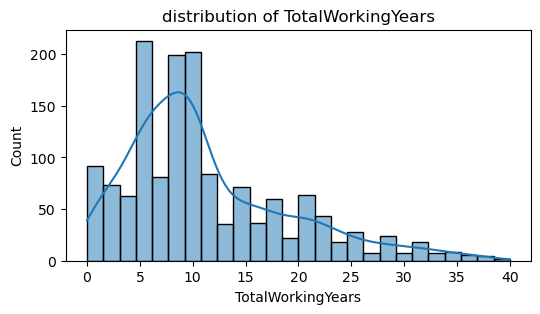

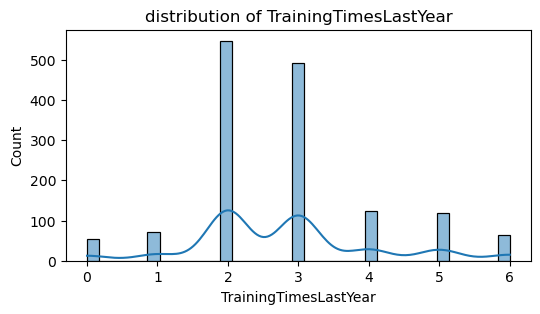

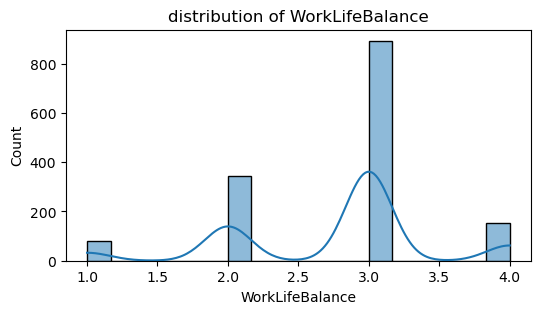

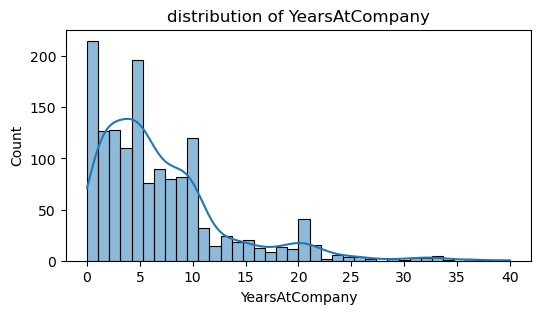

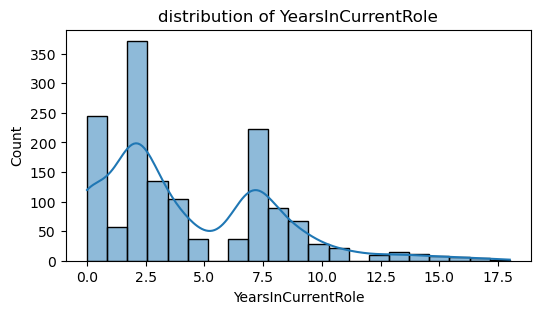

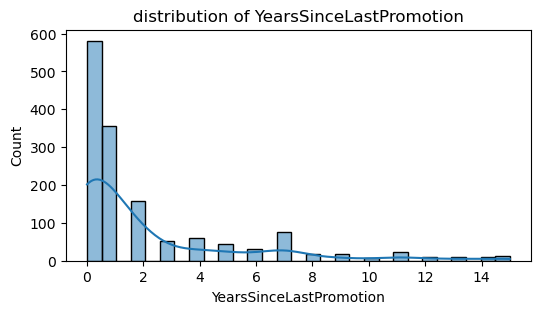

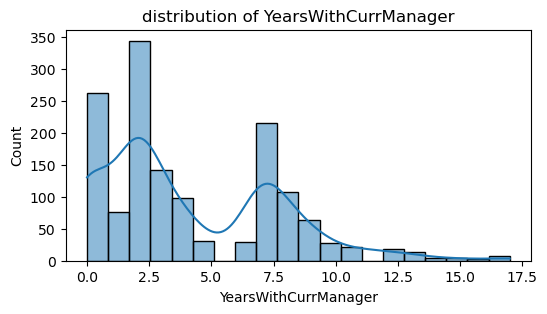

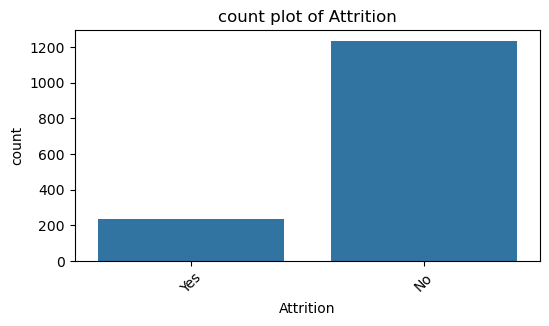

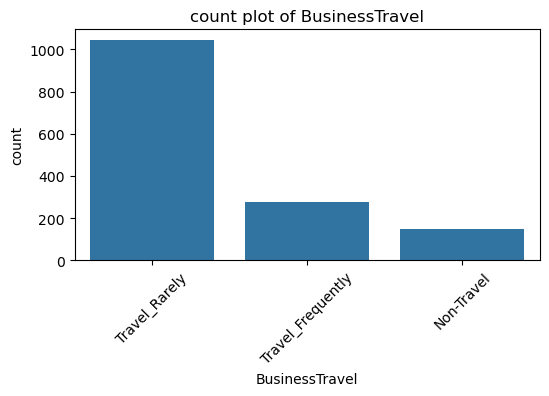

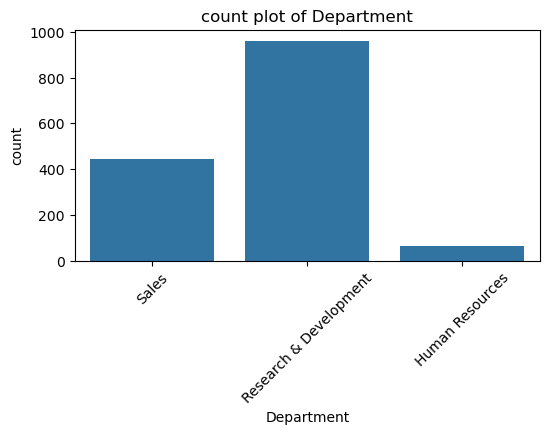

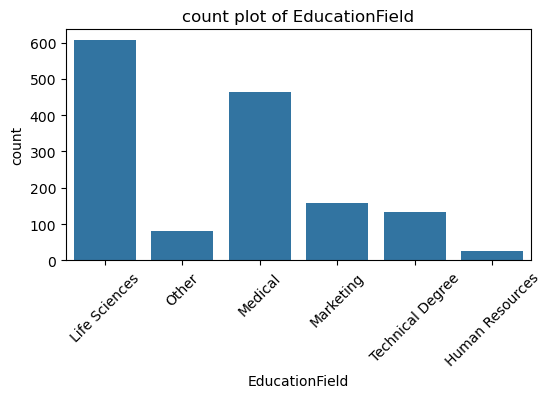

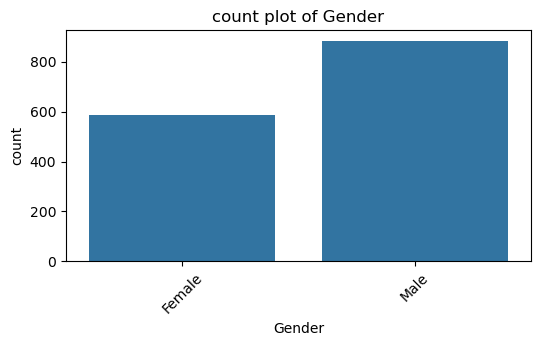

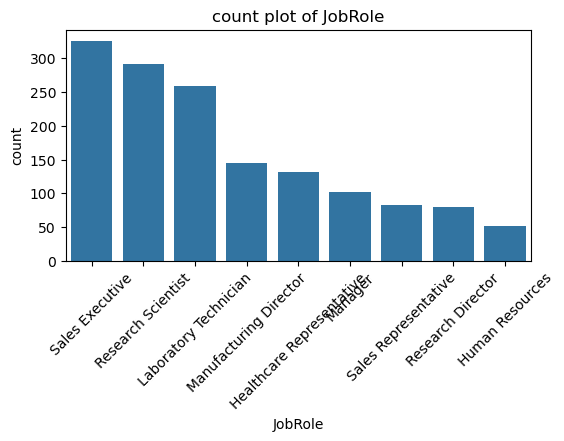

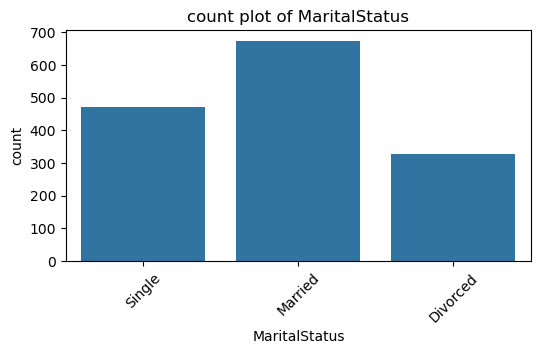

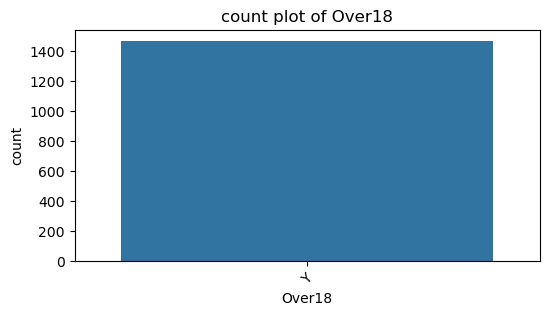

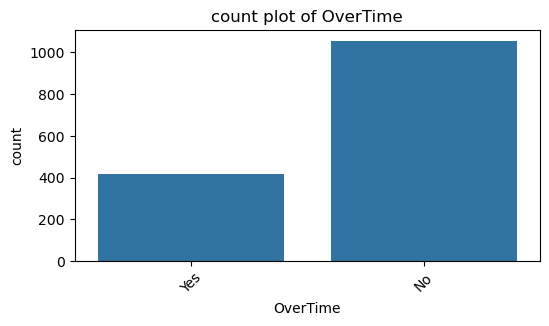

In [ ]:
#6 univariate analysis
#distribution of numerical features
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    plt.figure(figsize=(6,3))
    sns.histplot(df[col], kde=True)
    plt.title(f'distribution of {col}')
    plt.show()

#Count Plot for Categorical Features
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    plt.figure(figsize=(6,3))
    sns.countplot(x=df[col])
    plt.title(f'count plot of {col}')
    plt.xticks(rotation=45)
    plt.show()

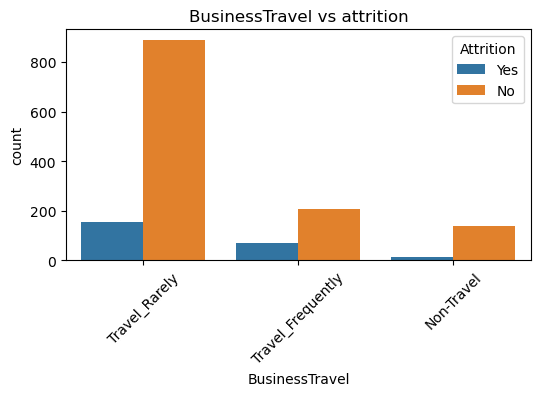

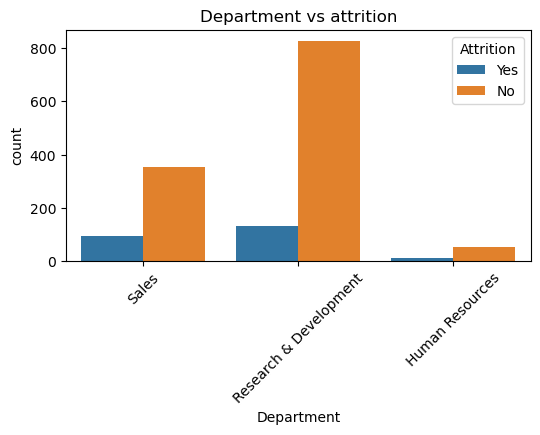

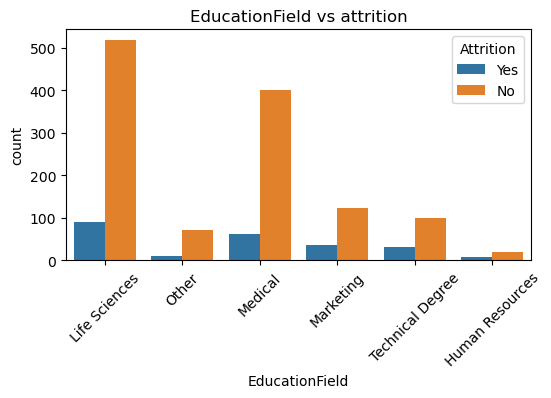

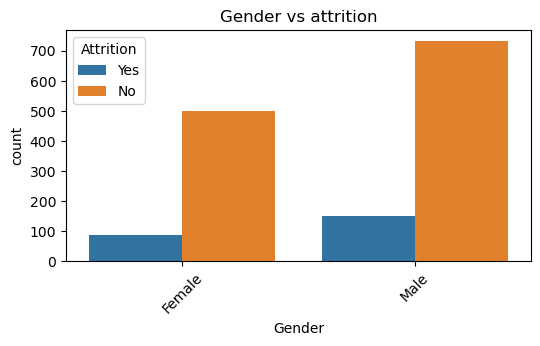

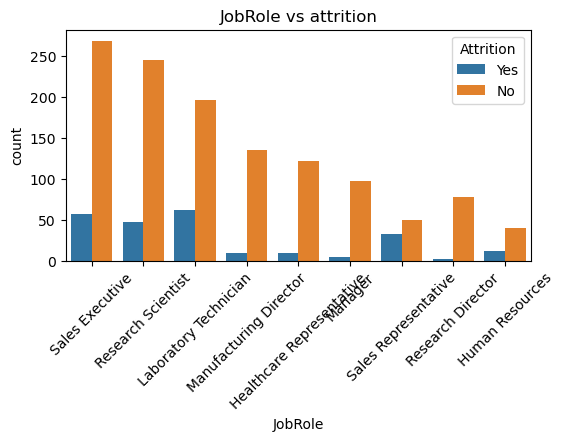

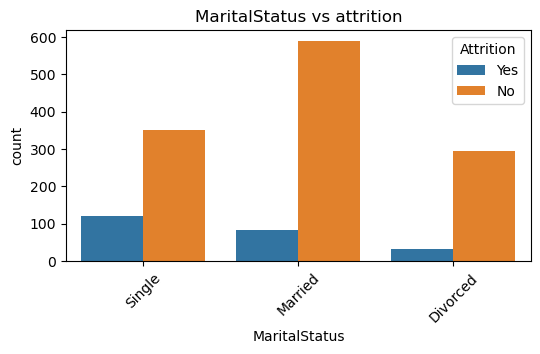

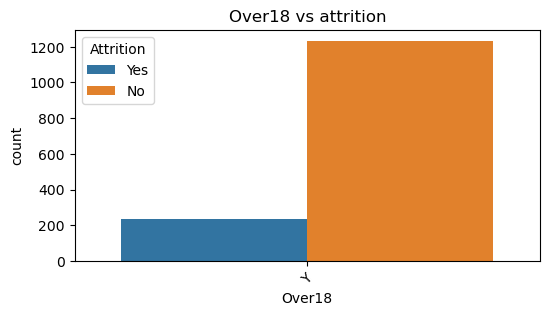

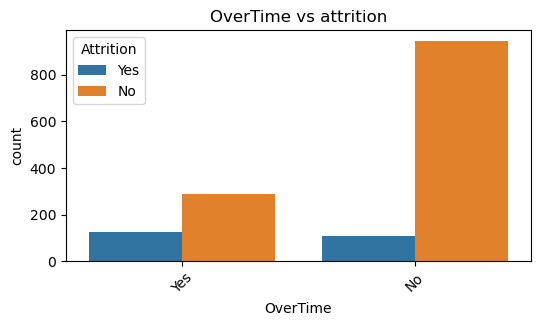

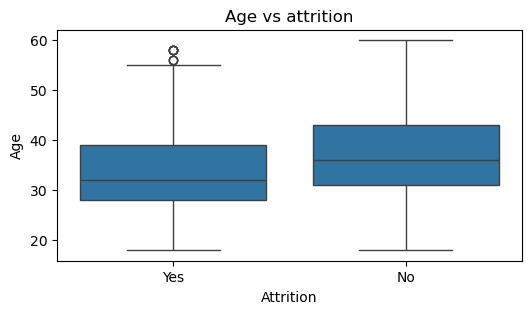

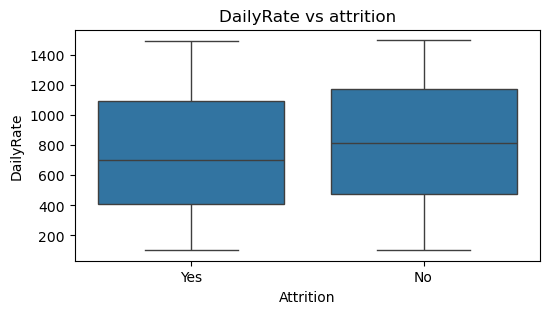

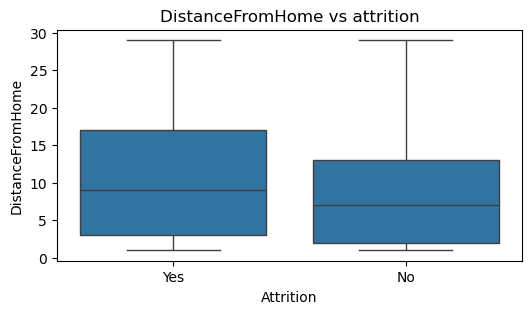

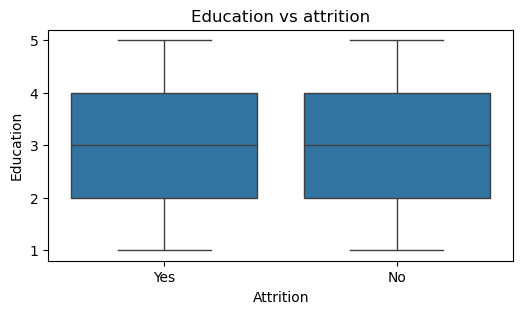

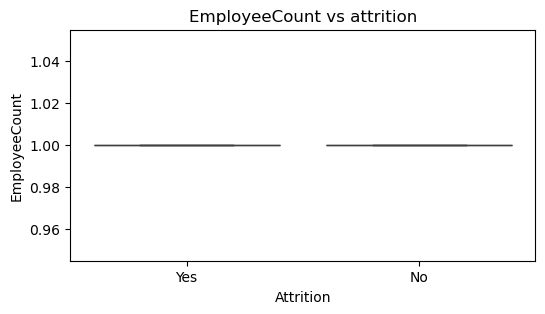

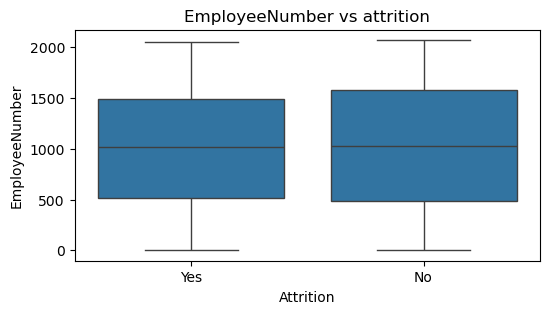

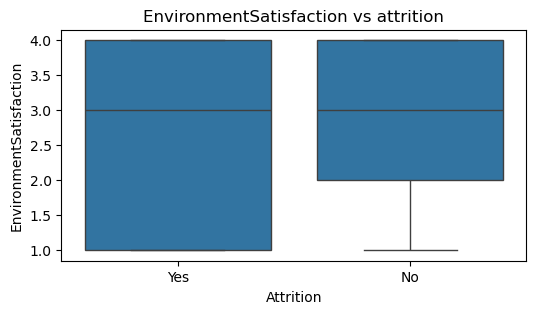

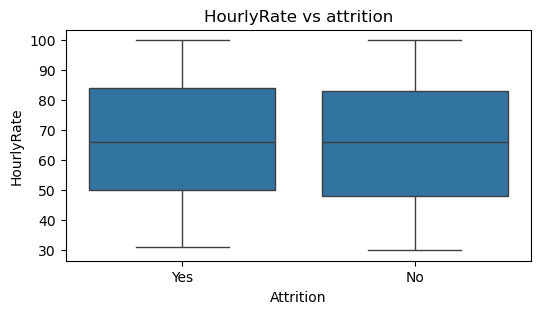

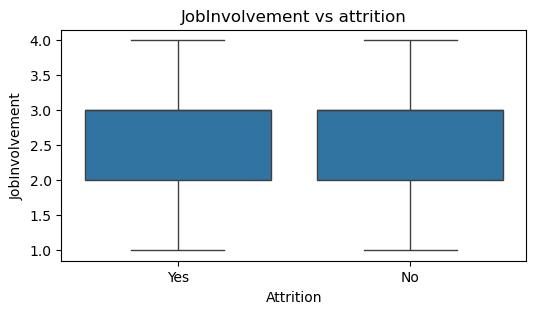

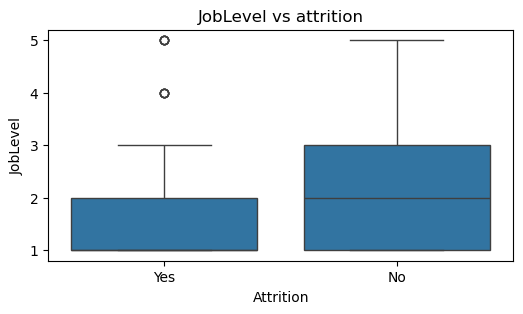

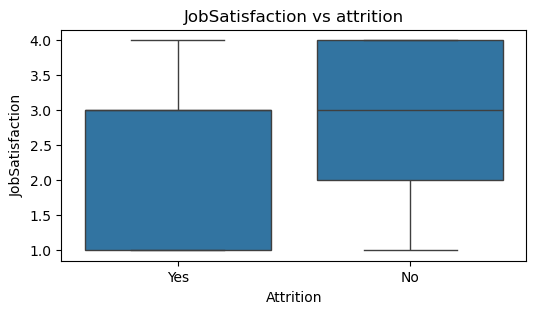

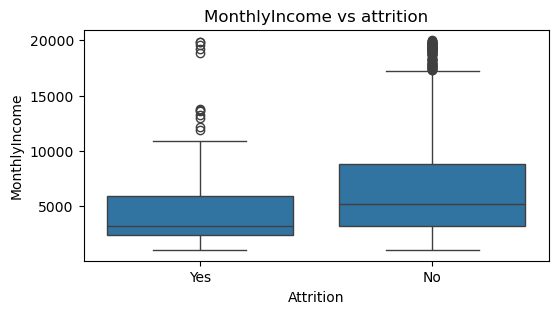

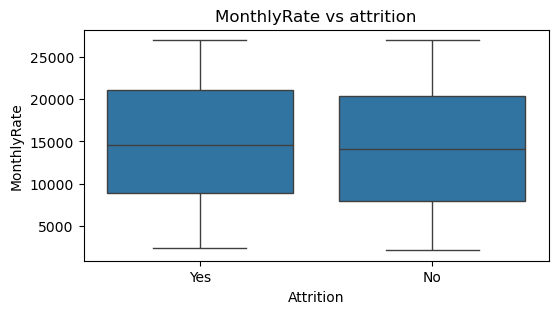

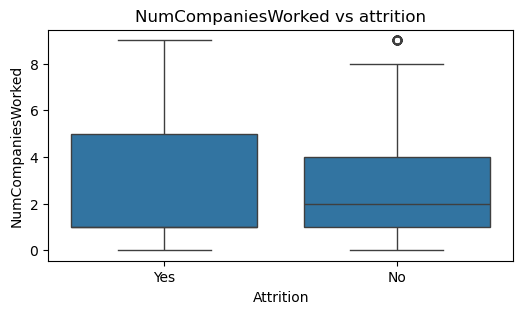

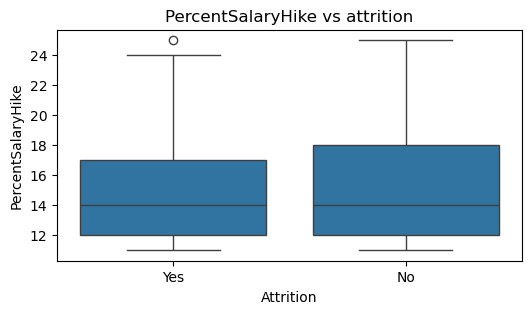

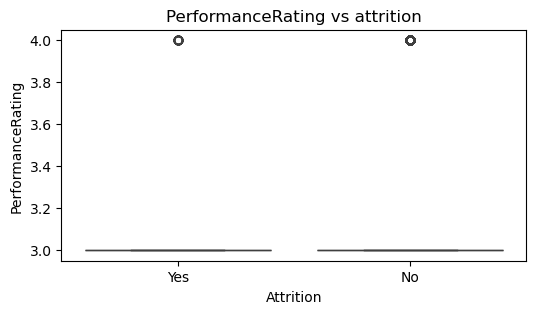

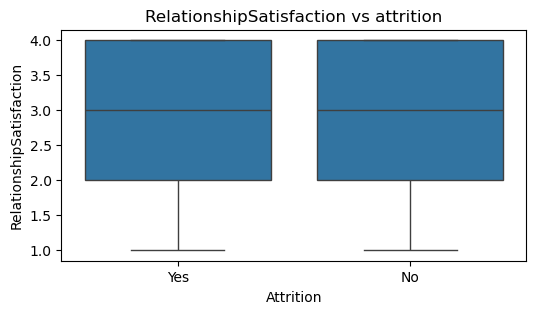

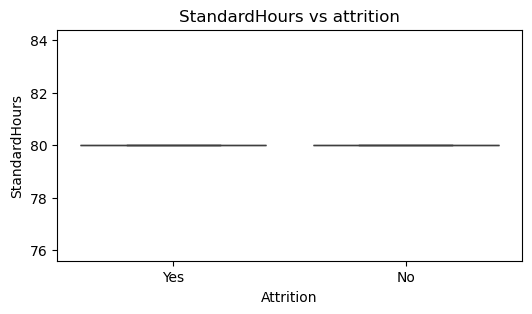

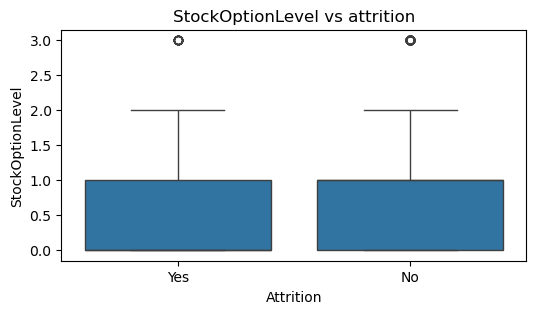

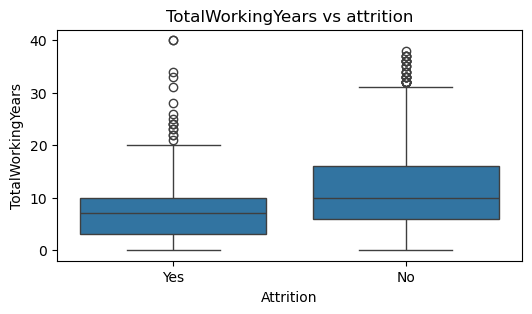

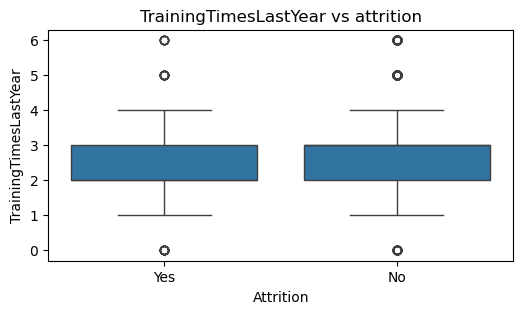

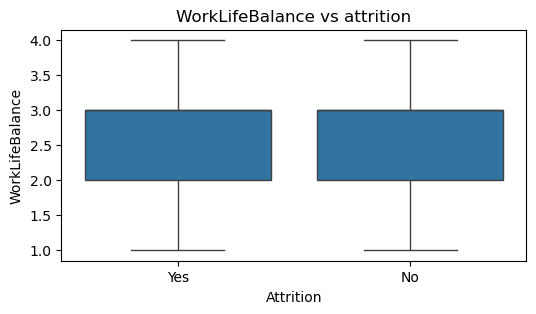

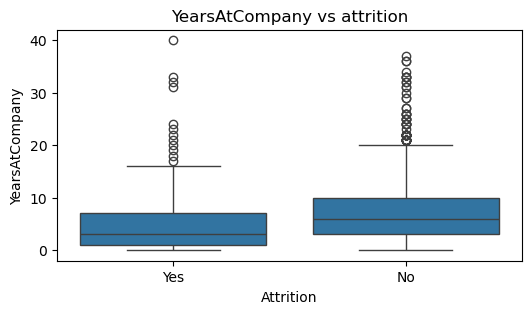

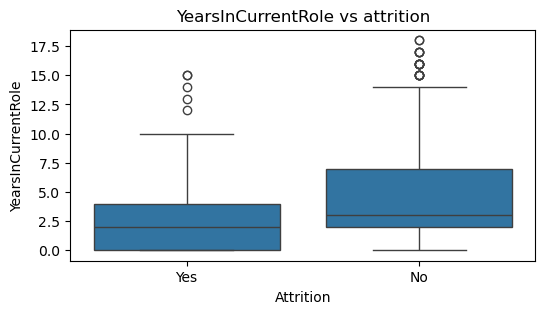

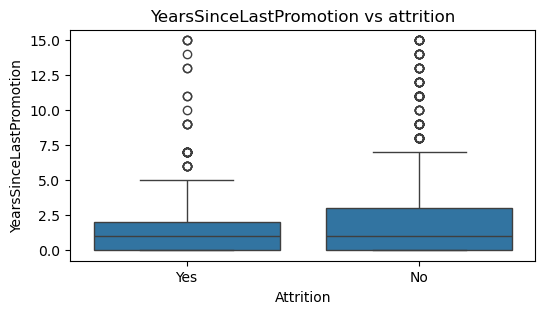

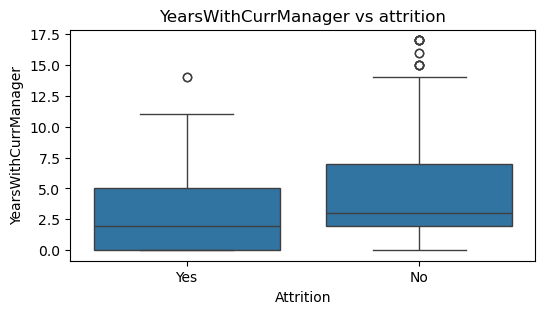

In [ ]:
# First, import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your data into a DataFrame
# Replace 'your_data_file.csv' with the actual path to your data file
df = pd.read_csv(r"C:\Users\HPadmin\Downloads\HR-Employee-Attrition.csv")  # or use pd.read_excel() for Excel files

# Define the categorical and numerical columns
# Get categorical columns (excluding 'Attrition' if it exists in the dataframe)
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
if 'Attrition' in cat_cols:
    cat_cols.remove('Attrition')  # Remove 'Attrition' from categorical columns if it exists

# Get numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Bivariate analysis
# Attrition vs categorical features
for col in cat_cols:
    if col != 'attrition':
        plt.figure(figsize=(6,3))
        sns.countplot(x=col, hue='Attrition', data=df)  # Note: 'Attrition' is capitalized here
        plt.title(f'{col} vs attrition')
        plt.xticks(rotation=45)
        plt.show()

# Attrition vs numerical features
for col in num_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x='Attrition', y=col, data=df)
    plt.title(f'{col} vs attrition')
    plt.show()

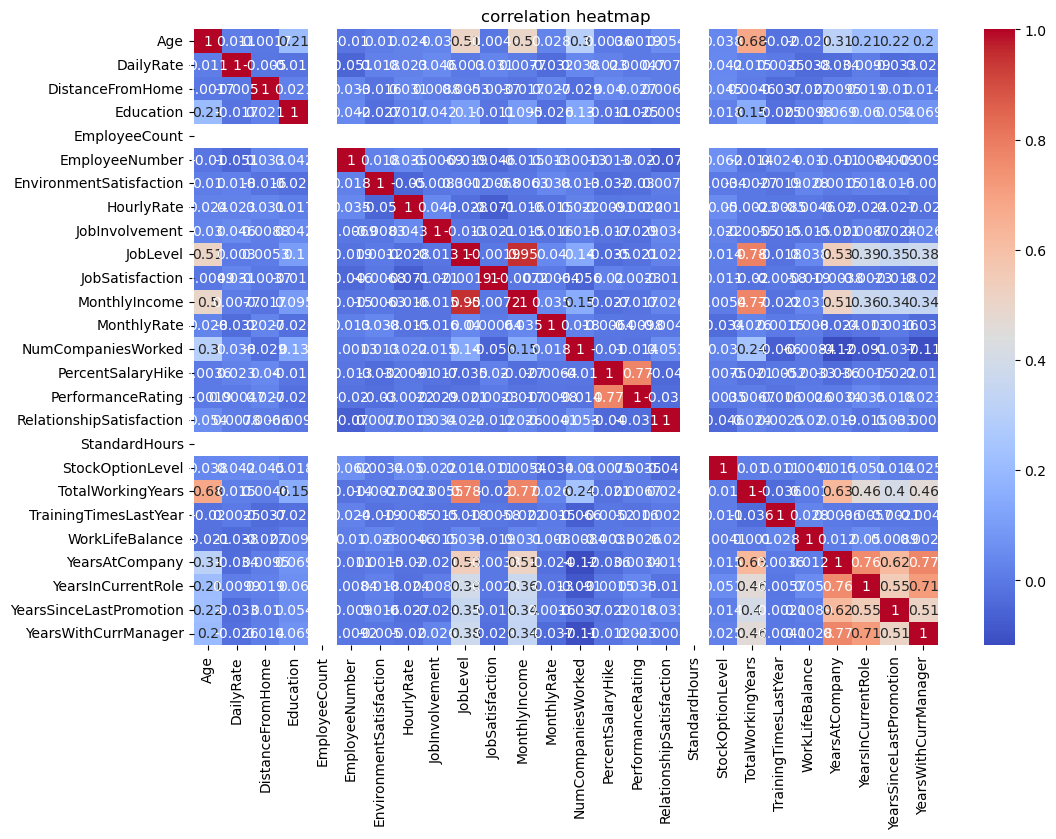

In [ ]:
#8 correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('correlation heatmap')
plt.show()

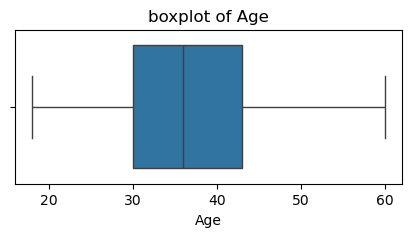

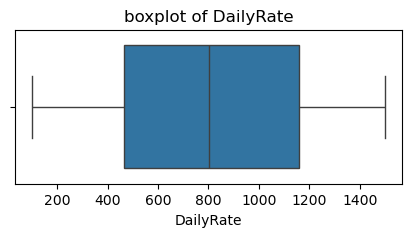

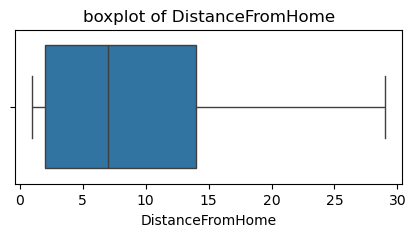

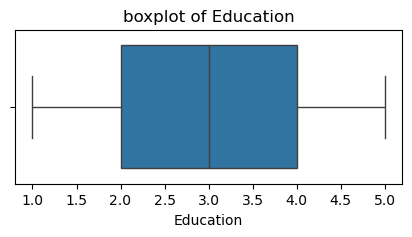

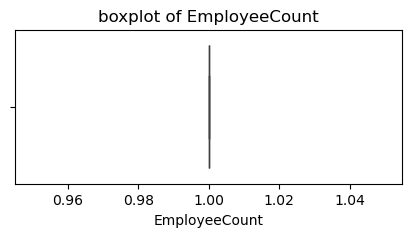

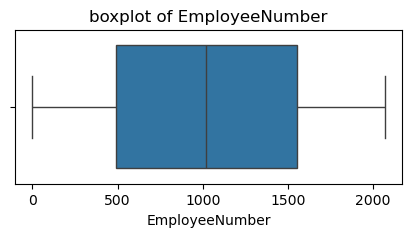

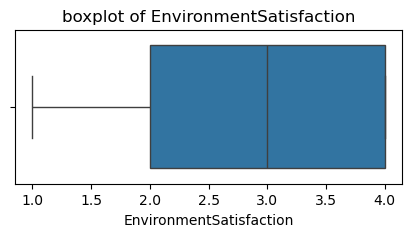

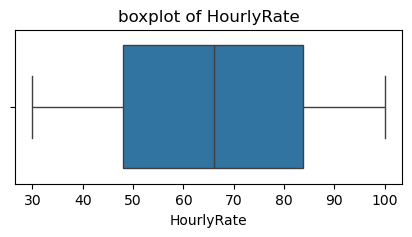

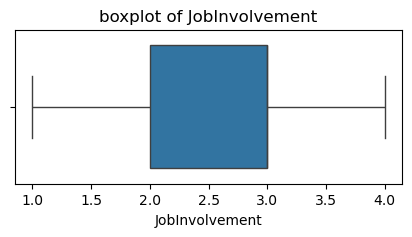

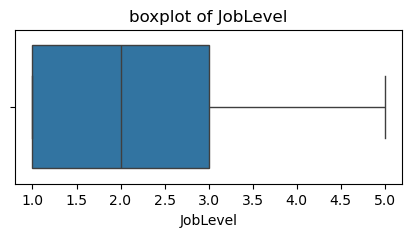

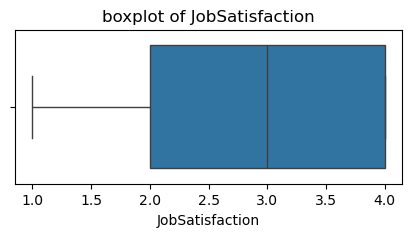

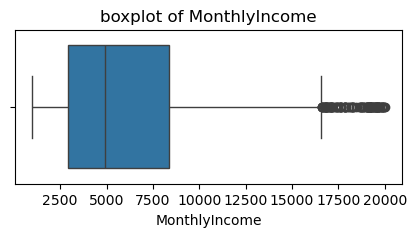

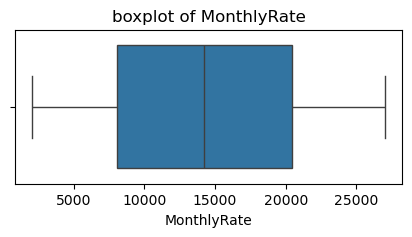

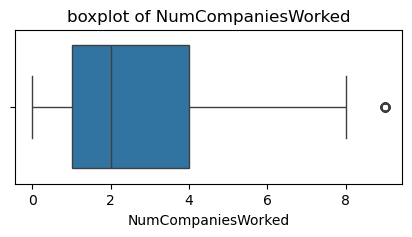

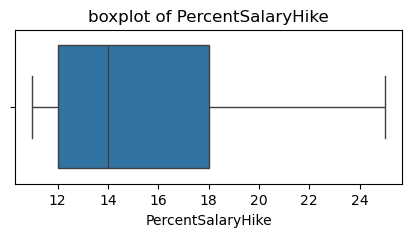

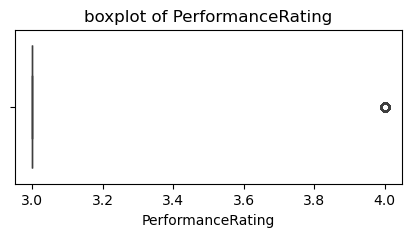

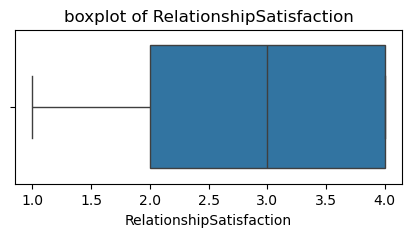

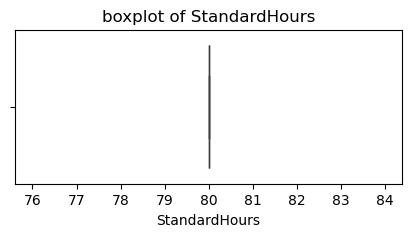

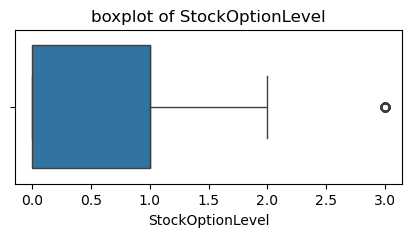

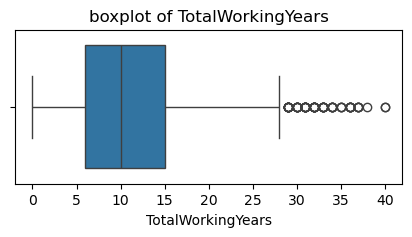

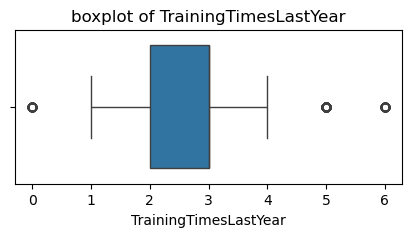

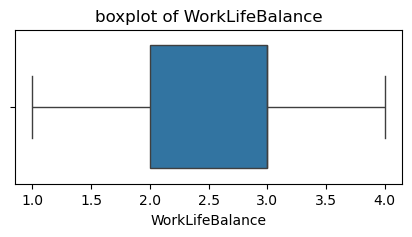

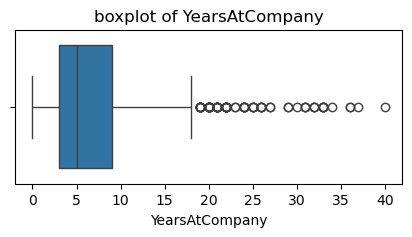

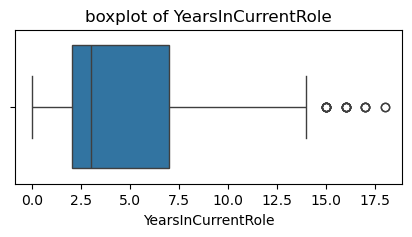

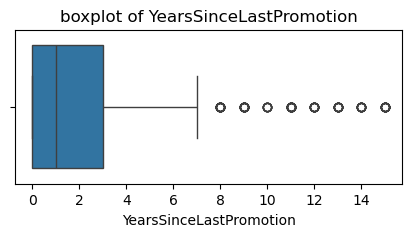

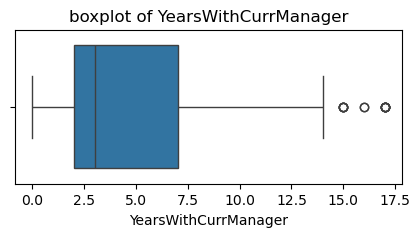

In [ ]:
#9 detect&handling outliers
#detect using boxplot
for col in num_cols:
    plt.figure(figsize=(5,2))
    sns.boxplot(x=df[col])
    plt.title(f'boxplot of {col}')
    plt.show()

#handling using IQR method
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

In [ ]:
#10 encoding
#label encoding
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

#one_hot encoding
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
2,37,1,2,1373,1,2,2,4,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,0,1,1392,1,3,4,1,1,5,...,3,80,0,8,3,3,8,7,3,0
5,32,0,1,1005,1,2,2,1,1,8,...,3,80,0,8,2,2,7,7,3,6
11,29,0,2,153,1,15,2,1,1,15,...,4,80,0,10,3,3,9,5,0,8
12,31,0,2,670,1,26,1,1,1,16,...,4,80,1,5,1,2,5,2,4,3


In [ ]:
#11 feature scaling
from sklearn.preprocessing import StandardScaler, MinMaxScaler

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame (optional)
X = pd.DataFrame(X_scaled, columns=X.columns)

print(y.unique())

[ 2.17474325 -0.4598244 ]


In [ ]:
#12 separate Features & target
X = df.drop('Attrition', axis=1)
y = df['Attrition']
y = y.map({'Yes': 1, 'No': 0})

In [ ]:
#13. Train-Test Split
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# First, make sure X and y are properly defined
# For example, if you're working with a DataFrame df:
# X = df.drop('target_column', axis=1)
# y = df['target_column']

# Check if y has any non-NaN values
if len(y) > 0 and y.notna().any():
    # First, check and handle NaN values in y
    # Option 1: Remove rows with NaN values in y
    mask = ~pd.isna(y)
    X_clean = X[mask]
    y_clean = y[mask]

    # Check if we still have data after cleaning
    if len(y_clean) > 0:
        # Now perform the train-test split on the cleaned data
        X_train, X_test, y_train, y_test = train_test_split(
            X_clean, y_clean, test_size=0.2, random_state=42,
            stratify=y_clean if len(set(y_clean)) > 1 else None  # Only stratify if there are multiple classes
        )
        print(f"Train set size: {len(X_train)}, Test set size: {len(X_test)}")
    else:
        print("No valid data after removing NaN values.")
else:
    print("The target variable y contains no valid data (all NaN or empty).")

The target variable y contains no valid data (all NaN or empty).


In [ ]:
#14. Handle Imbalance using SMOTE
from imblearn.over_sampling import SMOTE

# Convert continuous target to discrete classes if this is a classification problem
# For example, if you're working with a binary classification where the threshold is 0.5:
y_train_discrete = (y_train > 0.5).astype(int)  # Convert to 0 and 1

# Now apply SMOTE on the discrete classes
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train_discrete)

print(y_train_resampled.value_counts())

Attrition
0    461
1    461
Name: count, dtype: int64


In [ ]:
#15 train classification models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

# Changed to regression models since the target variable is continuous
models = {
     "Linear Regression": LinearRegression(),  # Changed from LogisticRegression
     "Decision Tree": DecisionTreeRegressor(),  # Changed from DecisionTreeClassifier
     "Random Forest": RandomForestRegressor(),  # Changed from RandomForestClassifier
     "KNN": KNeighborsRegressor()  # Changed from KNeighborsClassifier
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model


In [ ]:
#16 model evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    # Check if the model has predict_proba method (classification model)
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:,1]

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred),
            "Recall": recall_score(y_test, y_pred),
            "F1 Score": f1_score(y_test, y_pred),
            "ROC-AUC": roc_auc_score(y_test, y_prob)
        })

        print(f"\n{name} Confusion Matrix:")
        print(confusion_matrix(y_test, y_pred))
    else:
        # For regression models, use appropriate metrics
        from sklearn.metrics import mean_squared_error, r2_score

        results.append({
            "Model": name,
            "MSE": mean_squared_error(y_test, y_pred),
            "R2": r2_score(y_test, y_pred)
        })

        print(f"\n{name} is a regression model - no confusion matrix available")


Linear Regression is a regression model - no confusion matrix available

Decision Tree is a regression model - no confusion matrix available

Random Forest is a regression model - no confusion matrix available

KNN is a regression model - no confusion matrix available


In [ ]:
#17 cross validation
from sklearn.model_selection import cross_val_score
import numpy as np
import pandas as pd

# First, check if there are any valid samples in y
mask = ~np.isnan(y)
X_clean = X[mask]
y_clean = y[mask]

# Check if we have enough samples for cross-validation
if len(y_clean) > 0:
    # Adjust the number of folds if necessary
    n_splits = min(5, len(y_clean))

    for name, model in models.items():
        scores = cross_val_score(model, X_clean, y_clean, cv=n_splits, scoring='accuracy')
        print(f"{name} CV Accuracy: {scores.mean():.4f}")
else:
    print("Error: No valid samples found. All target values are NaN.")
    # You might want to investigate why all y values are NaN
    print(f"Total samples: {len(y)}, Valid samples: {np.sum(mask)}")

Error: No valid samples found. All target values are NaN.
Total samples: 699, Valid samples: 0


In [ ]:
#18 hyperparameter tuning
#gridsearcgCV
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

# Use RandomForestRegressor for continuous target values
grid = GridSearchCV(RandomForestRegressor(), param_grid, cv=3, scoring='r2')
grid.fit(X_train, y_train)

best_rf = grid.best_estimator_

#randomizedsearchCV (KNN)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neighbors import KNeighborsRegressor  # Changed to KNeighborsRegressor for regression tasks

param_dist = {
    'n_neighbors': range(3, 15),
    'weights': ['uniform', 'distance']
}

# Use KNeighborsRegressor instead of KNeighborsClassifier for continuous target values
rand = RandomizedSearchCV(KNeighborsRegressor(), param_dist, cv=3, n_iter=10)
rand.fit(X_train, y_train)

best_knn = rand.best_estimator_

In [ ]:
results_df = pd.DataFrame(results)

# First, let's check what columns are actually available in the DataFrame
print("Available columns:", results_df.columns.tolist())

# After seeing the available columns, sort by the correct column name
# For example, if the F1 score column is actually named 'f1' or 'F1':
# results_df.sort_values(by='f1', ascending=False)

# If you're not sure which column to sort by, you can inspect the first few rows
print("\nFirst few rows of the DataFrame:")
print(results_df.head())

# Once you know the correct column name, uncomment and modify this line:
# sorted_df = results_df.sort_values(by='correct_column_name', ascending=False)

Available columns: ['Model', 'MSE', 'R2']

First few rows of the DataFrame:
               Model       MSE        R2
0  Linear Regression  0.767180  0.221846
1      Decision Tree  1.735237 -0.760057
2      Random Forest  0.756935  0.232238
3                KNN  1.092703 -0.108333


In [ ]:
# 20 select best model
# First check what columns are actually available in the DataFrame
print(results_df.columns)

# Initialize best_model as None to avoid NameError
best_model = None

try:
    # Try with 'mean_test_score' first
    best_model = results_df.sort_values(by='mean_test_score', ascending=False).iloc[0]
except KeyError:
    # If that fails, look at available columns and choose an appropriate one
    print("Column 'mean_test_score' not found. Available columns are:")
    print(results_df.columns)

    # Example of using a different column - replace with appropriate column from your data
    # Uncomment and modify the line below with an appropriate column name
    # best_model = results_df.sort_values(by='test_score', ascending=False).iloc[0]

    # If you're not sure which column to use, you can also just display the DataFrame
    print("Please examine the DataFrame and choose an appropriate column for sorting:")
    print(results_df.head())

# Only print best_model if it was successfully defined
if best_model is not None:
    print(best_model)
else:
    print("Could not determine best model. Please specify the correct column for sorting.")

Index(['Model', 'MSE', 'R2'], dtype='object')
Column 'mean_test_score' not found. Available columns are:
Index(['Model', 'MSE', 'R2'], dtype='object')
Please examine the DataFrame and choose an appropriate column for sorting:
               Model       MSE        R2
0  Linear Regression  0.767180  0.221846
1      Decision Tree  1.735237 -0.760057
2      Random Forest  0.756935  0.232238
3                KNN  1.092703 -0.108333
Could not determine best model. Please specify the correct column for sorting.


In [ ]:
#21 final insights
feature_importance = trained_models["Random Forest"].feature_importances_
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": feature_importance
}).sort_values(by="Importance", ascending=False)

importance_df.head(10)

,Feature,Importance
17,MonthlyIncome,0.108751
2,DailyRate,0.075839
0,Age,0.067390
27,TotalWorkingYears,0.062579
11,HourlyRate,0.061466
4,DistanceFromHome,0.056470
8,EmployeeNumber,0.049385
18,MonthlyRate,0.048483
21,OverTime,0.046860
19,NumCompaniesWorked,0.034424
